# Fitting polynomials to sin(x)

When studying Deep Learning it's good to practice the basics rigorously. One example that I found is a nice way to test yourself is by training a linear model to fit sin(x).

Starting with the deep learning basics, most work can be reduced to the following:
1. Specification of a dataset
2. Model
3. Cost/Loss function
4. Optimisation procedure

We'll start by working through these steps and then see what improvements can be made. Our goal wil be to fit the best possible linear polynomial model to sin(x).

## Dataset

For our dataset, we want to predict sin(x), so we should generate some data points. We decide to model x over the range of 0 to 2$\pi$, and then calculate y using sin with a little added noise.

In [1]:
import torch
import math
import matplotlib.pyplot as plt

print("Using cuda:", torch.cuda.is_available())

Using cuda: False


In [2]:
# Generate dataset
x = torch.linspace(0, 2 * math.pi, 100)
y = torch.sin(x) + torch.randn(x.shape) * 0.1
dataset = torch.stack([x, y], dim=1)

x_scaled = 2 * (x - x.min()) / (x.max() - x.min()) - 1

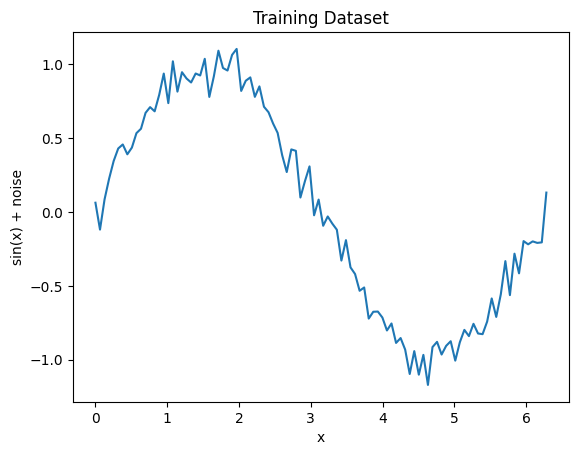

In [3]:
plt.plot(x, y)
plt.xlabel("x")
plt.ylabel("sin(x) + noise")
plt.title("Training Dataset")
plt.show()

## Model

For a model, we'll train a linear combination of $N$ polynomials represented by the following function:

$$ f(x) = \sum_{n=0}^N w_nx^n\ $$

Note that this includes the bias as $w_0$.

There are many other ways you could fit sin(x) which would work a lot better, but we choose this model for its didatic merit.

While we're not doing a full-blown neural network, we can still define our model using torch for practice.

Model weights: Parameter containing:
tensor([-0.0500,  0.8753, -0.7196], requires_grad=True)


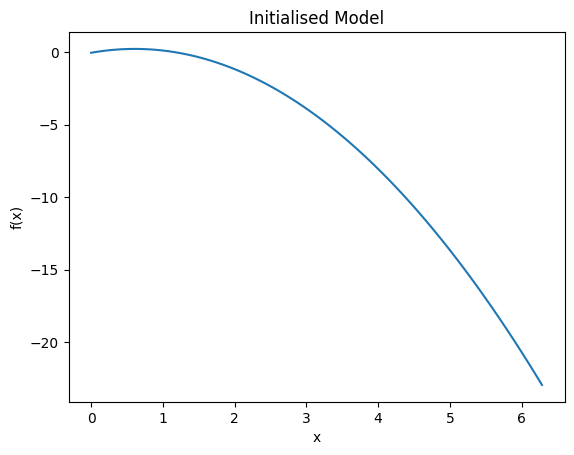

In [4]:
class PolynomialModel(torch.nn.Module):
    """
    Create model with polynomials up to order N
    """
    def __init__(self, N: int = 0):
        super().__init__()
        self.N = N
        # Define our weights randomly
        w = torch.randn(N+1)
        # Set the weights as torch parameters to track
        self.w = torch.nn.Parameter(w)

    def forward(self, x):
        # Get the powers to use
        powers = torch.arange(self.N + 1)       # Shape: N
        # Use broadcasting to raise x to powers
        x_powers = x.unsqueeze(-1) ** powers    # Shape: s x N
        # Take the weighted sum
        return (x_powers @ self.w) # Shape: s

# Model up to quadratic
model = PolynomialModel(N=2)

print("Model weights:", model.w)

# Check model works
plt.plot(x, model(x).detach())
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Initialised Model")
plt.show()

## Loss Function

The task at hand is to fit a linear model to a continuous dataset. A natural choice here is Mean Squared Error (MSE). It corresponds to maximising the likelihood of the data if the noise is gaussian distributed. While our approximation error (fitting polynomial to sin) is not necessarily normally distributed, MSE is still good in practice.

MSE loss is represented by:

$$L = \frac{1}{N}\sum^N_i (f(x) - y_i)^2$$

Defining it is a simple one-liner with torch.

In [5]:
loss_fn = torch.nn.MSELoss()

## Optimisation Procedure

Now that we have a model, and a loss, we need to decide on how we'll optimise the model.

Given we're working with a linear model, we can directly derive the optimisations required.

We want to minimise our loss function, meaning we want the derivative wrt. our parameters to be 0. Starting with just one sample, $i$:

$$\frac{\partial L_i}{\partial w_n} = \frac{\partial}{\partial w_n}(f(x_i) - y_i)^2$$
Applying the chain rule, we get
$$2(f(x_i)  - y_i)\frac{\partial f(x)}{\partial w_n}$$
Since we have a linear combination, the nth weight derivative is affected only by the relevant power of x, giving:
$$2(f(x_i)  - y_i)x^n$$

So this gives us the graident of the loss function with respect to one of the gradient terms. To get the loss for different weights we simply vary the value of $n$. For the entire dataset, it is possible to take an average of the gradients as the loss is defined as the sum across the samples.

Now, to optimise, we can apply gradient descent:

$$ w_n \rightarrow w_n - lr \frac{\partial L}{\partial w_n}$$

where $lr$ is our learning rate. This can be implemented directly with torch.

In [6]:
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)

We can now also define our training loop.

In [7]:
def train(model, loss_fn, optimizer, x: torch.Tensor, y: torch.Tensor, n_epoch: int = 10, verbose: bool = True):
    """
    Train a model using the given loss function and optimizer.
    """
    for i in range(n_epoch):
        optimizer.zero_grad()
        # Model sin(x) using current model
        y_pred = model(x)
        loss = loss_fn(y_pred, y)
        # Calculate gradients with backprop
        loss.backward()
        # Update parameters
        optimizer.step()
        if verbose:
            print(f"Epoch {i} loss: {loss.item()}")

model = PolynomialModel(N=2)
loss_fn = torch.nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)

train(model, loss_fn, optimizer, x, y, 10)

Epoch 0 loss: 130.74143981933594
Epoch 1 loss: 16.402013778686523
Epoch 2 loss: 3.0924859046936035
Epoch 3 loss: 1.5405094623565674
Epoch 4 loss: 1.3568506240844727
Epoch 5 loss: 1.3324458599090576
Epoch 6 loss: 1.3265880346298218
Epoch 7 loss: 1.3229020833969116
Epoch 8 loss: 1.3194823265075684
Epoch 9 loss: 1.3161066770553589


This very basic training loop shows how we can reduce the loss over time and get closer to our target (sin(x)). Let's also plot the before and after for our model.

Epoch 0 loss: 14.63537311553955
Epoch 1 loss: 2.7220630645751953
Epoch 2 loss: 1.3318842649459839
Epoch 3 loss: 1.1663718223571777
Epoch 4 loss: 1.1433992385864258
Epoch 5 loss: 1.1370316743850708
Epoch 6 loss: 1.132614016532898
Epoch 7 loss: 1.1284399032592773
Epoch 8 loss: 1.124311089515686
Epoch 9 loss: 1.120204210281372


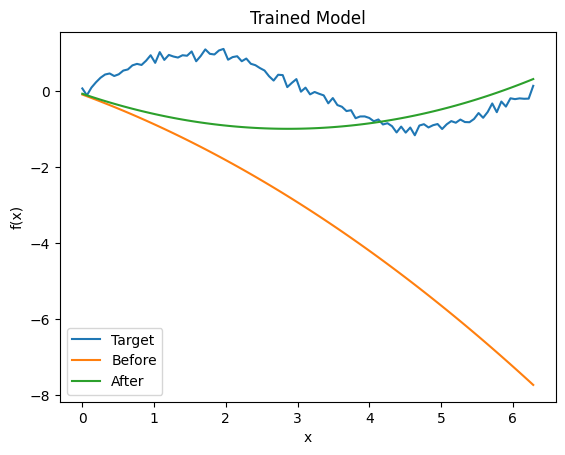

In [8]:
model = PolynomialModel(N=2)
loss_fn = torch.nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)

plt.plot(x, y)
plt.plot(x, model(x).detach())

train(model, loss_fn, optimizer, x, y, 10)
plt.plot(x, model(x).detach())
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Trained Model")
plt.legend(["Target", "Before", "After"])
plt.show()


We can clearly see that the model has gone from very poorly fitting, to reasonably close.

With the basics out of the way, let's see what we can do now as we expand the model.

## Next Steps

To improve the model, we can increase the value of N, let's try just 3, giving us a $x^3$ term.

In [9]:
model = PolynomialModel(N=3)
loss_fn = torch.nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)
train(model, loss_fn, optimizer, x, y, 10)



Epoch 0 loss: 34976.1328125
Epoch 1 loss: 10906920.0
Epoch 2 loss: 3403325184.0
Epoch 3 loss: 1061953667072.0
Epoch 4 loss: 331365685919744.0
Epoch 5 loss: 1.0339741205109146e+17
Epoch 6 loss: 3.2263523847691567e+19
Epoch 7 loss: 1.0067322963125963e+22
Epoch 8 loss: 3.1413473533189545e+24
Epoch 9 loss: 9.802076651107325e+26


Uh-oh! Our loss has now spiralled out of control. What went wrong?

The key is in our gradient update steps. Recall that the weight updates are proportial to the corresponding power of x.

$$ w_n \rightarrow w_n - 2lr(f(x_i)  - y_i)x^n$$

This means that for our largest value of x, the update is multiplied by $6^3 = 216$. This, combined with our learning rate of $10^{-3}$ and an inital error from random initialisation on the order of 10 means that the update is on the order of 1, a relatively large update when our weights start out distributed with a standard deviation of 1!

These unstable updates lead to weights quickly growing out of control and loss follows.

So how can we fix this? Are we limited to polynomials of order two? Of course not!

While there are MANY options to improve, let's address a couple of common ones that would apply to many problems:
* **Gradient clipping**: since the issue here is that our gradients are very large, we can clip the gradients to keep them at a reasonable value. A common approach is to clip them such that the norm is 1.
* **Normalisation**: We saw that the large gradient values are caused by raising x to very high powers. To avoid this being an issue, we can normalise the values of x. We can map the support [0,2$\pi$] to [-1,1]. By doing this, x will no longer cause the gradient to be so large; however we will still have issues of numerical instability as small numbers are shrunk.
* **Learning Rate**: Having a learning rate of $10^-3$ is typically reasonable, but we could decrease this to counter our large gradients. It can also be decreased over time to help us get finer estimates of our parameters.
* **Adam Optimizer**: the Adam optimizer integrates a few very helpful changes to the optimisation process. In particular, it uses adaptive learning rates as well as momentum which smooths out the gradient with previous updates.

Let's try implementing these in our loop.

Epoch 0 loss: 1.9046157598495483
Epoch 10 loss: 1.5885201692581177
Epoch 20 loss: 1.3169541358947754
Epoch 30 loss: 1.0893044471740723
Epoch 40 loss: 0.9037337303161621
Epoch 50 loss: 0.7561708688735962
Epoch 60 loss: 0.6436614990234375
Epoch 70 loss: 0.5577310919761658
Epoch 80 loss: 0.48907843232154846
Epoch 90 loss: 0.4331221282482147


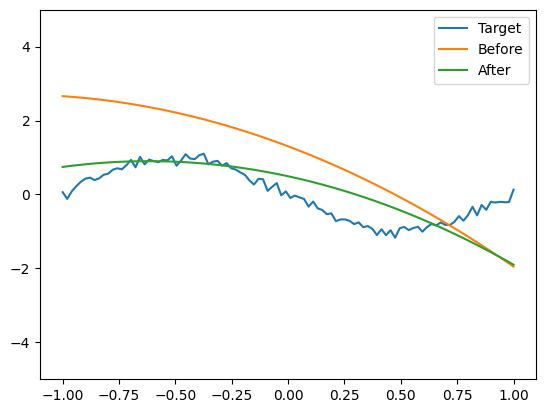

In [10]:
def train_new(model, loss_fn, optimizer, x: torch.Tensor, y: torch.Tensor, n_epoch: int = 10, verbose: bool = True):
    for i in range(n_epoch):
        optimizer.zero_grad()
        y_pred = model(x)
        loss = loss_fn(y_pred, y)
        # calculate gradients with backprop
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1)
        # update parameters
        if verbose and i % (n_epoch / 10) == 0:
            print(f"Epoch {i} loss: {loss.item()}")
        optimizer.step()


model = PolynomialModel(N=2)

loss_fn = torch.nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)

plt.plot(x_scaled, y)
plt.plot(x_scaled, model(x_scaled).detach())
train_new(model, loss_fn, optimizer, x_scaled, y, 100, verbose=True)
plt.plot(x_scaled, model(x_scaled).detach())
plt.ylim(-5, 5)
plt.legend(["Target", "Before", "After"])


Epoch 0 loss: 2.509209394454956
Epoch 100 loss: 0.3352455496788025
Epoch 200 loss: 0.22479566931724548
Epoch 300 loss: 0.1529003083705902
Epoch 400 loss: 0.10102801024913788
Epoch 500 loss: 0.06503896415233612
Epoch 600 loss: 0.04182478412985802
Epoch 700 loss: 0.027933290228247643
Epoch 800 loss: 0.020213494077324867
Epoch 900 loss: 0.01623004861176014


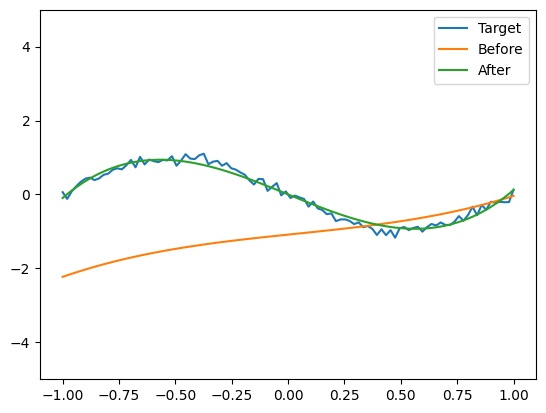

In [11]:
model = PolynomialModel(N=3)

loss_fn = torch.nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)

plt.plot(x_scaled, y)
plt.plot(x_scaled, model(x_scaled).detach())
train_new(model, loss_fn, optimizer, x_scaled, y, 1000, verbose=True)
plt.plot(x_scaled, model(x_scaled).detach())
plt.ylim(-5, 5)
plt.legend(["Target", "Before", "After"])


Epoch 0 loss: 2.5292856693267822
Epoch 100 loss: 0.6132433414459229
Epoch 200 loss: 0.08036978542804718
Epoch 300 loss: 0.020836012437939644
Epoch 400 loss: 0.016577405855059624
Epoch 500 loss: 0.01557192299515009
Epoch 600 loss: 0.014809587970376015
Epoch 700 loss: 0.01421423815190792
Epoch 800 loss: 0.013771922327578068
Epoch 900 loss: 0.013458873145282269


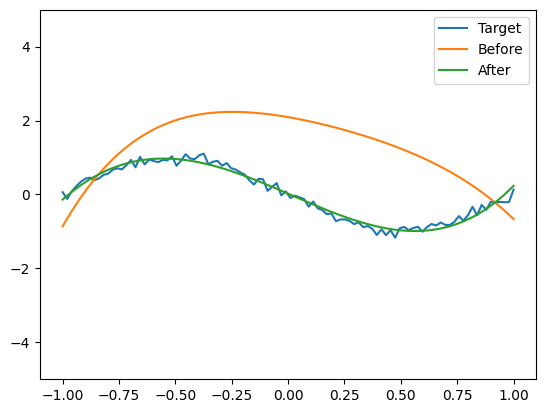

In [12]:
model = PolynomialModel(N=4)

loss_fn = torch.nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)

plt.plot(x_scaled, y)
plt.plot(x_scaled, model(x_scaled).detach())
train_new(model, loss_fn, optimizer, x_scaled, y, 1000, verbose=True)
plt.plot(x_scaled, model(x_scaled).detach())
plt.ylim(-5, 5)
plt.legend(["Target", "Before", "After"])


Epoch 0 loss: 1.1408095359802246
Epoch 100 loss: 0.14309708774089813
Epoch 200 loss: 0.09364036470651627
Epoch 300 loss: 0.05900983884930611
Epoch 400 loss: 0.038768220692873
Epoch 500 loss: 0.028716392815113068
Epoch 600 loss: 0.024289168417453766
Epoch 700 loss: 0.022417794913053513
Epoch 800 loss: 0.021516848355531693
Epoch 900 loss: 0.02091926522552967


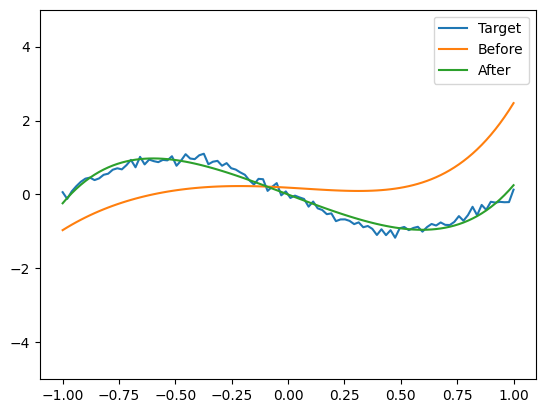

In [13]:
model = PolynomialModel(N=5)

loss_fn = torch.nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)

plt.plot(x_scaled, y)
plt.plot(x_scaled, model(x_scaled).detach())
train_new(model, loss_fn, optimizer, x_scaled, y, 1000, verbose=True)
plt.plot(x_scaled, model(x_scaled).detach())
plt.ylim(-5, 5)
plt.legend(["Target", "Before", "After"])


Epoch 0 loss: 3.5074427127838135
Epoch 1000 loss: 0.05344557389616966
Epoch 2000 loss: 0.015795176848769188
Epoch 3000 loss: 0.011376026086509228
Epoch 4000 loss: 0.01052425429224968
Epoch 5000 loss: 0.009545913897454739
Epoch 6000 loss: 0.008561010472476482
Epoch 7000 loss: 0.007836228236556053
Epoch 8000 loss: 0.0075104995630681515
Epoch 9000 loss: 0.0074412464164197445


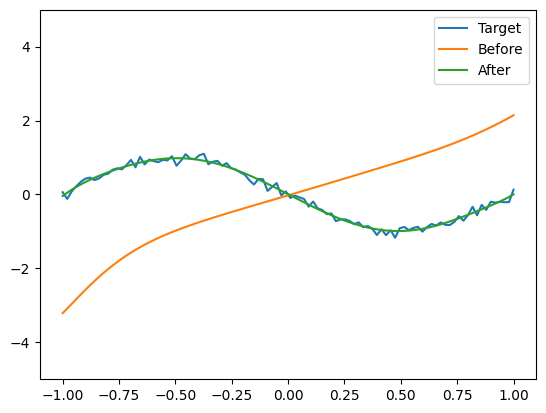

In [14]:
model = PolynomialModel(N=10)

loss_fn = torch.nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)

plt.plot(x_scaled, y)
plt.plot(x_scaled, model(x_scaled).detach())
train_new(model, loss_fn, optimizer, x_scaled, y, 10000, verbose=True)
plt.plot(x_scaled, model(x_scaled).detach())
plt.ylim(-5, 5)
plt.legend(["Target", "Before", "After"])


So we now see that we can fit large degree polynomials to our dataset with just a few modifications.

Feel free to play around with the different parameters, for example: how does using a higher learning rate change the results? What if we only normalise the data, do we need Adam?

A few other fun exercises:
* What about the 2D case where y = sin(x1)sin(x2), i.e. the multi-dimensional case?
* Instead of the standard polynomials, what about using a different basis?

Finally, as a bonus, we plot the results for different values of n.

early stop: 2729
Final weights for N=1: [ 0.00626727 -0.9086234 ]
early stop: 3569
Final weights for N=2: [ 0.00214991 -0.9084426   0.01216173]
early stop: 9435
Final weights for N=3: [ 2.1498795e-03 -2.6343122e+00  1.2161867e-02  2.8197818e+00]
early stop: 7681
Final weights for N=4: [ 1.2749917e-03 -2.6362274e+00  2.4351656e-02  2.8226976e+00
 -1.5455350e-02]
early stop: 12654
Final weights for N=5: [-1.7206987e-03 -3.0748508e+00  5.0118875e-02  4.8323965e+00
 -4.3420892e-02 -1.7748150e+00]


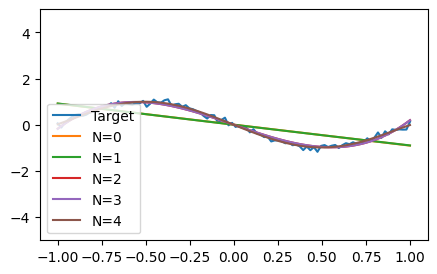

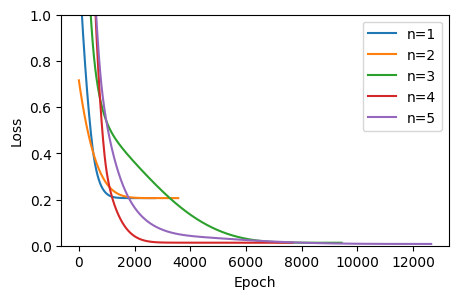

In [15]:
n_loss = {}
MAX_N = 5

plt.figure(figsize=(5,3))
# set y min and max
plt.ylim(-5, 5)
plt.plot(x_scaled, y)

for i in range(MAX_N):
    model = PolynomialModel(i+1)

    # Define loss function
    loss_fn = torch.nn.MSELoss()

    # Define optimizer
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

    n_epoch = 50000
    losses = []
    prev_loss = float('inf')
    loss_threshold = 1e-5
    for _ in range(n_epoch):
        optimizer.zero_grad()
        y_pred = model(x_scaled)
        loss = loss_fn(y_pred, y)
        # calculate gradients with backprop
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1)
        # print("grad", model.w.grad)
        # update parameters
        optimizer.step()
        # print(f"Epoch {i} loss: {loss.item()}")
        losses.append(loss.item())

        loss_diff = abs(loss.item() - sum(losses[-1000:])/1000)
        if _ > 1000 and loss_diff < loss_threshold:
            print("early stop:", _)
            break
        prev_loss = loss.item()

    n_loss[i+1] = losses
    # Plot the current model outputs
    plt.plot(x_scaled.detach().numpy(), model(x_scaled).detach().numpy())
    print(f"Final weights for N={i+1}:", model.w.detach().numpy())

plt.legend(["Target"] + ["N="+str(i) for i in range(MAX_N)])


plt.figure(figsize=(5,3))
for i in range(MAX_N):
    plt.plot(n_loss[i+1], label=f"n={i+1}")
plt.legend()
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.ylim(0,1)
plt.show()

In the results, we see
a significant jump as we go from n=2 to n=3. We can understand this by looking at the Taylor Series expansion of sin(x):

$$sin(x) = x - x^3/3! + x^5/5! + ...$$

The sine function can be represented by a sum of odd polynomials, so the quadratic doesn't help our model fit sine any better. As we add the fifth polynomial we don't see much of an improvement because loss is already so low.



Let's also look at the generality of our final model. We can extend the domain out to $4\pi$ giving us an extra oscillation in the sine curve.

Text(0.5, 1.0, 'f(x) over a wider range')

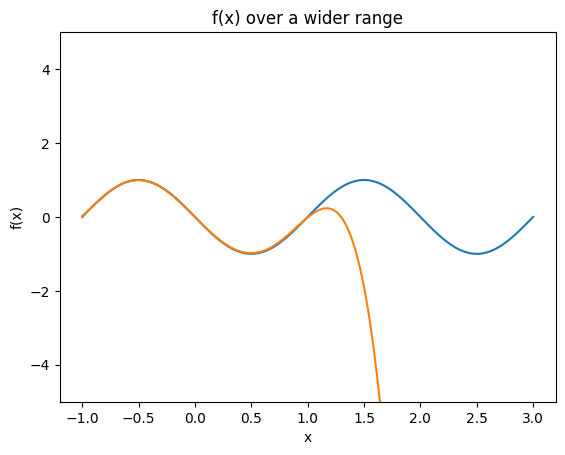

In [16]:
x_extended = torch.linspace(0, 4 * math.pi, 100)
x_extended_scaled = 2 * (x_extended - x.min()) / (x.max() - x.min()) - 1
plt.plot(x_extended_scaled, torch.sin(x_extended))
plt.plot(x_extended_scaled, model(x_extended_scaled).detach())
plt.ylim(-5,5)
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("f(x) over a wider range")

It's clear here that our model is overfit to our training data. This isn't surprising as we kept increasing the order of the polynomial, didn't use a validation set and pushed error to its limits.

Another exercise is to try re-training the model using a validation set (e.g. last 1/4 of the function).